1. Load prepared meetings

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

meetings = pd.read_csv(Path("data") / "meetings.csv")
print("shape", meetings.shape)
print(meetings["outcome"].value_counts().sort_index())
meetings.head()

shape (4184, 173)
outcome
1     690
2     839
3    1296
4    1359
Name: count, dtype: int64


   iid_woman  id_woman  gender_woman  idg_woman  condtn_woman  wave_woman  ...  attr5_1_man  sinc5_1_man  \
0          1       1.0             0          1             1           1  ...          NaN          NaN   
1          1       1.0             0          1             1           1  ...          NaN          NaN   
2          1       1.0             0          1             1           1  ...          NaN          NaN   
3          1       1.0             0          1             1           1  ...          NaN          NaN   
4          1       1.0             0          1             1           1  ...          NaN          NaN   

   intel5_1_man  fun5_1_man  amb5_1_man  outcome  
0           NaN         NaN         NaN        2  
1           NaN         NaN         NaN        2  
2           NaN         NaN         NaN        1  
3           NaN         NaN         NaN        1  
4           NaN         NaN         NaN        1  

[5 rows x 173 columns]

2. Describe

In [2]:
numeric_columns = meetings.select_dtypes(include="number").columns.tolist()
print("numeric columns", len(numeric_columns))
meetings[numeric_columns].describe().T

numeric columns 163


               count        mean         std  min    25%    50%    75%    max
iid_woman     4184.0  275.430210  157.881194  1.0  148.0  266.0  393.0  530.0
id_woman      4184.0    9.024140    5.574964  1.0    4.0    8.0   13.0   22.0
gender_woman  4184.0    0.000000    0.000000  0.0    0.0    0.0    0.0    0.0
idg_woman     4184.0   16.958652   11.075684  1.0    7.0   15.0   25.0   43.0
condtn_woman  4184.0    1.829828    0.375829  1.0    2.0    2.0    2.0    2.0
...              ...         ...         ...  ...    ...    ...    ...    ...
sinc5_1_man   2447.0    7.737229    1.593122  1.0    7.0    8.0    9.0   10.0
intel5_1_man  2447.0    8.342869    1.326707  4.0    8.0    8.0    9.0   10.0
fun5_1_man    2447.0    7.350633    1.937616  2.0    6.0    8.0    9.0   10.0
amb5_1_man    2447.0    7.489170    1.902516  1.0    6.0    8.0    9.0   10.0
outcome       4184.0    2.794455    1.069119  1.0    2.0    3.0    4.0    4.0

[163 rows x 8 columns]

3. Missing values

In [3]:
empty_cells = int(meetings.isna().sum().sum())
all_cells = meetings.size
print("empty cells", empty_cells)
print("all cells", all_cells)
print("empty share", empty_cells / all_cells)

empty_share_by_column = meetings.isna().mean().sort_values(ascending=False)
display(empty_share_by_column[empty_share_by_column >= 0.2])

expnum_woman      0.791587
expnum_man        0.780593
mn_sat_man        0.694073
tuition_man       0.647467
income_man        0.572897
mn_sat_woman      0.557122
tuition_woman     0.496176
attr5_1_man       0.415153
fun5_1_man        0.415153
sinc5_1_man       0.415153
amb5_1_man        0.415153
intel5_1_man      0.415153
undergra_man      0.415153
amb5_1_woman      0.412285
intel5_1_woman    0.412285
fun5_1_woman      0.412285
attr5_1_woman     0.412285
sinc5_1_woman     0.412285
undergra_woman    0.410373
income_woman      0.405832
shar4_1_woman     0.230163
intel4_1_woman    0.224904
fun4_1_woman      0.224904
sinc4_1_woman     0.224904
attr4_1_woman     0.224904
amb4_1_woman      0.224904
amb4_1_man        0.224187
intel4_1_man      0.224187
fun4_1_man        0.224187
shar4_1_man       0.224187
sinc4_1_man       0.224187
attr4_1_man       0.224187
positin1_man      0.219407
positin1_woman    0.219407
dtype: float64

empty cells 60568
all cells 723832
empty share 0.08367687529703025


4. Erroneous values

Preference points should sum to about 100. Ages outside 18-55 would be suspicious. Scorecard ratings were removed earlier.

In [4]:
preference_point_columns_woman = [
    "attr1_1_woman", "sinc1_1_woman", "intel1_1_woman",
    "fun1_1_woman", "amb1_1_woman", "shar1_1_woman",
]
preference_point_columns_man = [
    "attr1_1_man", "sinc1_1_man", "intel1_1_man",
    "fun1_1_man", "amb1_1_man", "shar1_1_man",
]

preference_sum_woman = (
    meetings.groupby("iid_woman")[preference_point_columns_woman]
    .first()
    .sum(axis=1, min_count=6)
)
preference_sum_man = (
    meetings.groupby("iid_man")[preference_point_columns_man]
    .first()
    .sum(axis=1, min_count=6)
)

print(
    "preference sum |100-sum| > 1, women",
    int((preference_sum_woman.sub(100).abs() > 1).sum()),
    "of",
    len(preference_sum_woman),
)
print(
    "preference sum |100-sum| > 1, men",
    int((preference_sum_man.sub(100).abs() > 1).sum()),
    "of",
    len(preference_sum_man),
)
print("age_woman min/max", meetings["age_woman"].min(), meetings["age_woman"].max())
print("age_man min/max", meetings["age_man"].min(), meetings["age_man"].max())
print(
    "rows with age outside 18-55",
    int(
        (
            meetings["age_woman"].between(18, 55, inclusive="both").eq(False)
            | meetings["age_man"].between(18, 55, inclusive="both").eq(False)
        ).sum()
    ),
)

preference sum |100-sum| > 1, women 3 of 274
preference sum |100-sum| > 1, men 6 of 277
age_woman min/max 19.0 55.0
age_man min/max 18.0 42.0
rows with age outside 18-55 94


5. Column types: categorical, text, timestamps

No timestamp columns. `wave` is an event id, not a calendar date. Integer codes stay coded for now; raw text is high-cardinality and better replaced by `field_cd` / `career_c` in the model.

In [5]:
categorical_code_columns = [
    "gender_woman", "gender_man",
    "condtn_woman", "condtn_man",
    "samerace_woman", "samerace_man",
    "race_woman", "race_man",
    "race_o_woman", "race_o_man",
    "goal_woman", "goal_man",
    "field_cd_woman", "field_cd_man",
    "career_c_woman", "career_c_man",
    "date_woman", "date_man",
    "go_out_woman", "go_out_man",
]
text_columns = [
    "field_woman", "field_man",
    "career_woman", "career_man",
    "from_woman", "from_man",
    "undergra_woman", "undergra_man",
    "zipcode_woman", "zipcode_man",
]
event_id_columns = ["wave_woman", "wave_man"]
timestamp_columns = []

print("categorical code columns", len(categorical_code_columns))
print("text columns", len(text_columns))
print("event id columns", event_id_columns)
print("timestamp columns", timestamp_columns)

for column in categorical_code_columns:
    print(column, "nunique", meetings[column].nunique(dropna=False))

for column in text_columns:
    print(column, "nunique", meetings[column].nunique(dropna=True))

categorical code columns 20
text columns 10
event id columns ['wave_woman', 'wave_man']
timestamp columns []
gender_woman nunique 1
gender_man nunique 1
condtn_woman nunique 2
condtn_man nunique 2
samerace_woman nunique 2
samerace_man nunique 2
race_woman nunique 6
race_man nunique 6
race_o_woman nunique 6
race_o_man nunique 6
goal_woman nunique 7
goal_man nunique 7
field_cd_woman nunique 17
field_cd_man nunique 19
career_c_woman nunique 15
career_c_man nunique 15
date_woman nunique 8
date_man nunique 8
go_out_woman nunique 8
go_out_man nunique 8
field_woman nunique 136
field_man nunique 104
career_woman nunique 162
career_man nunique 168
from_woman nunique 145
from_man nunique 151
undergra_woman nunique 117
undergra_man nunique 132
zipcode_woman nunique 221
zipcode_man nunique 200


6. Outliers (box-plots)

Decision: keep ages 18-55. Keep high income and tuition. Do not drop rows from IQR alone. Preference sums far from 100 stay as survey noise.

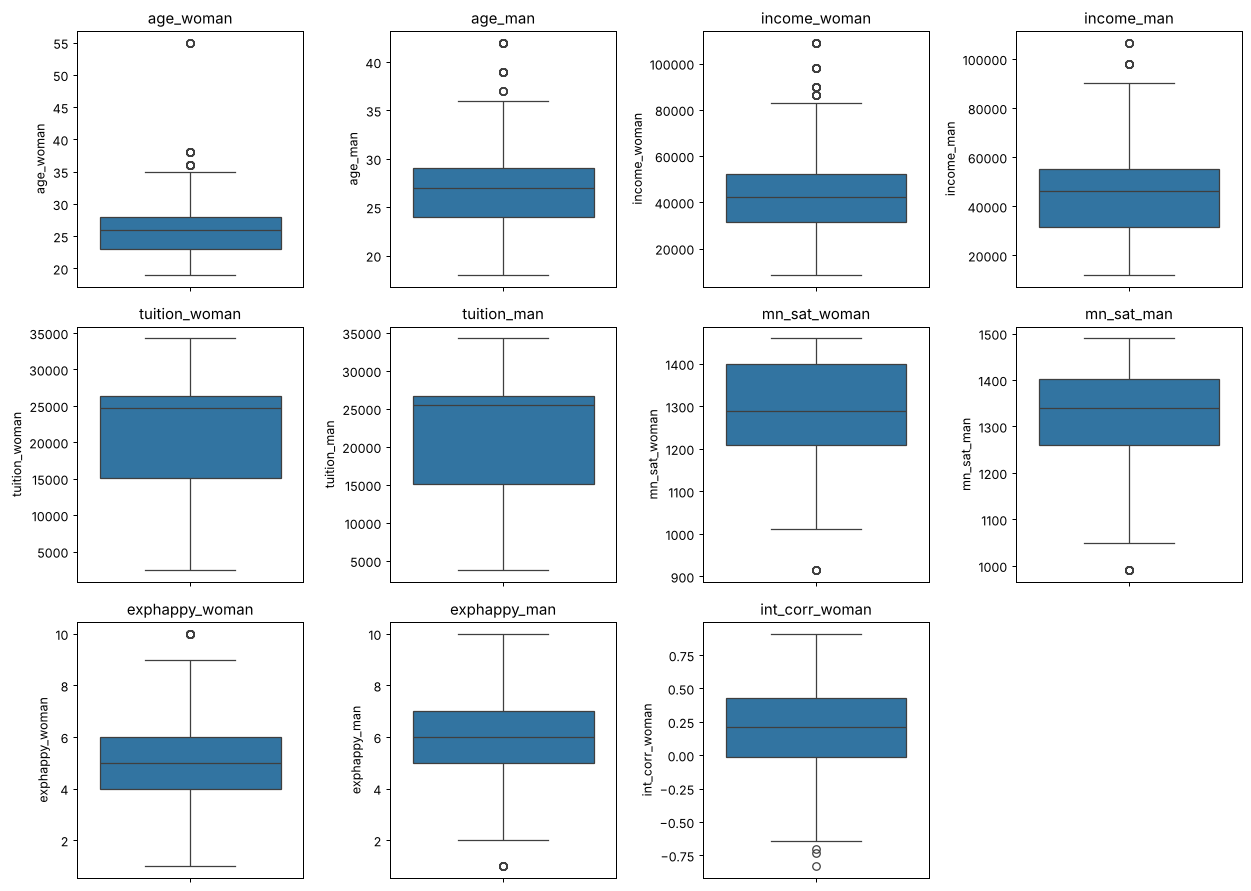

outlier rows dropped: 0


In [6]:
boxplot_columns = [
    "age_woman", "age_man",
    "income_woman", "income_man",
    "tuition_woman", "tuition_man",
    "mn_sat_woman", "mn_sat_man",
    "exphappy_woman", "exphappy_man",
    "int_corr_woman",
]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.ravel()
for axis, column in zip(axes, boxplot_columns):
    sns.boxplot(y=meetings[column], ax=axis)
    axis.set_title(column)
for axis in axes[len(boxplot_columns):]:
    axis.axis("off")
fig.tight_layout()
plt.show()

print("outlier rows dropped: 0")

7. Histograms and log transforms

1-10 and 0-100 preference scales stay untransformed. Log1p only for income, tuition, and median SAT.

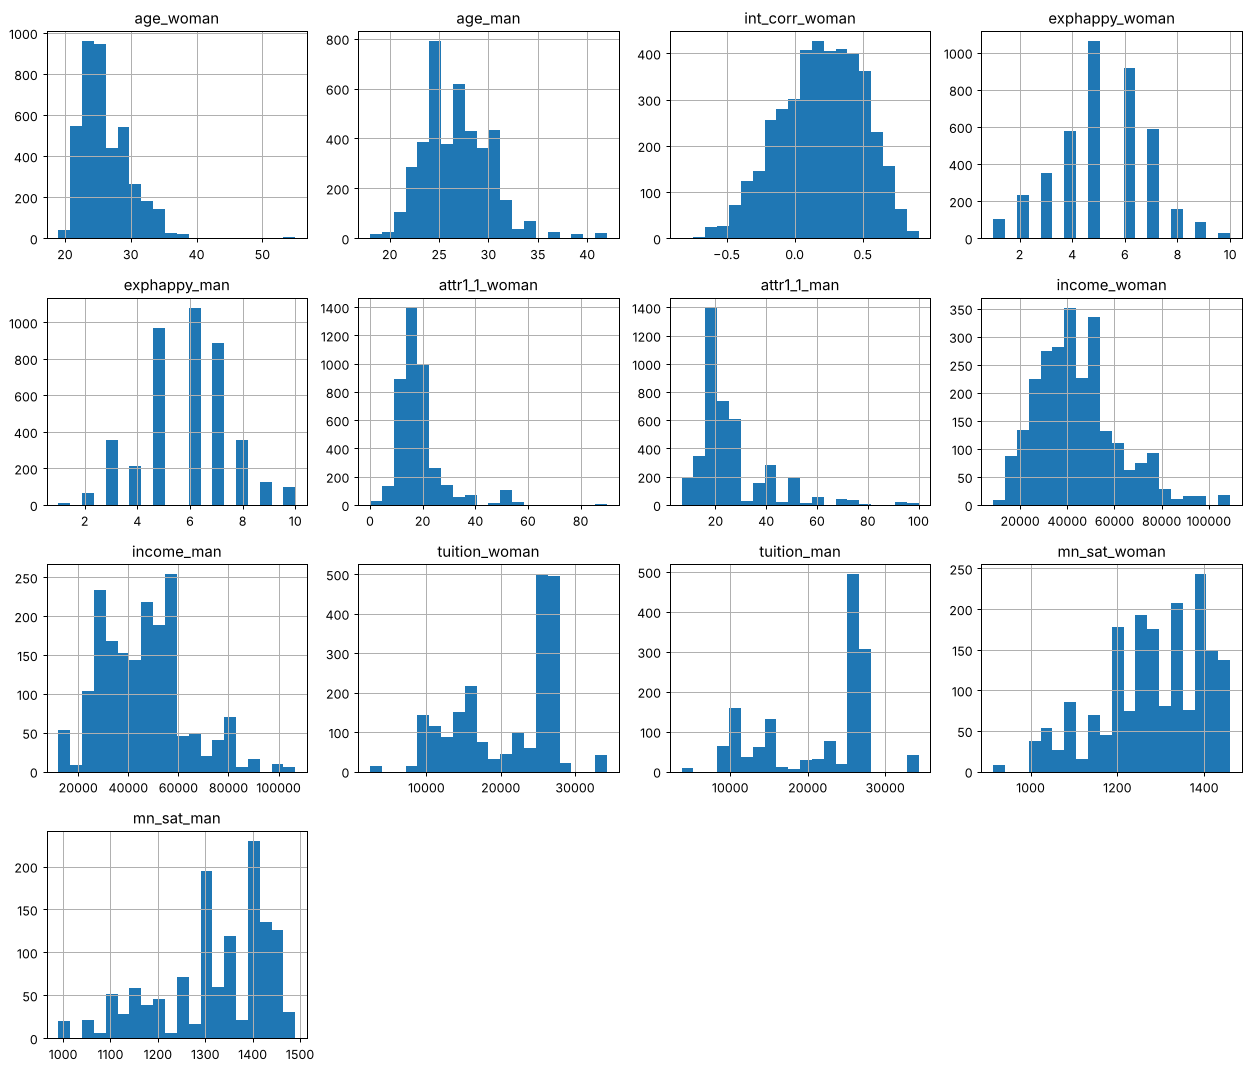

In [7]:
histogram_columns = [
    "age_woman", "age_man",
    "int_corr_woman",
    "exphappy_woman", "exphappy_man",
    "attr1_1_woman", "attr1_1_man",
    "income_woman", "income_man",
    "tuition_woman", "tuition_man",
    "mn_sat_woman", "mn_sat_man",
]

fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.ravel()
for axis, column in zip(axes, histogram_columns):
    meetings[column].dropna().hist(ax=axis, bins=20)
    axis.set_title(column)
for axis in axes[len(histogram_columns):]:
    axis.axis("off")
fig.tight_layout()
plt.show()

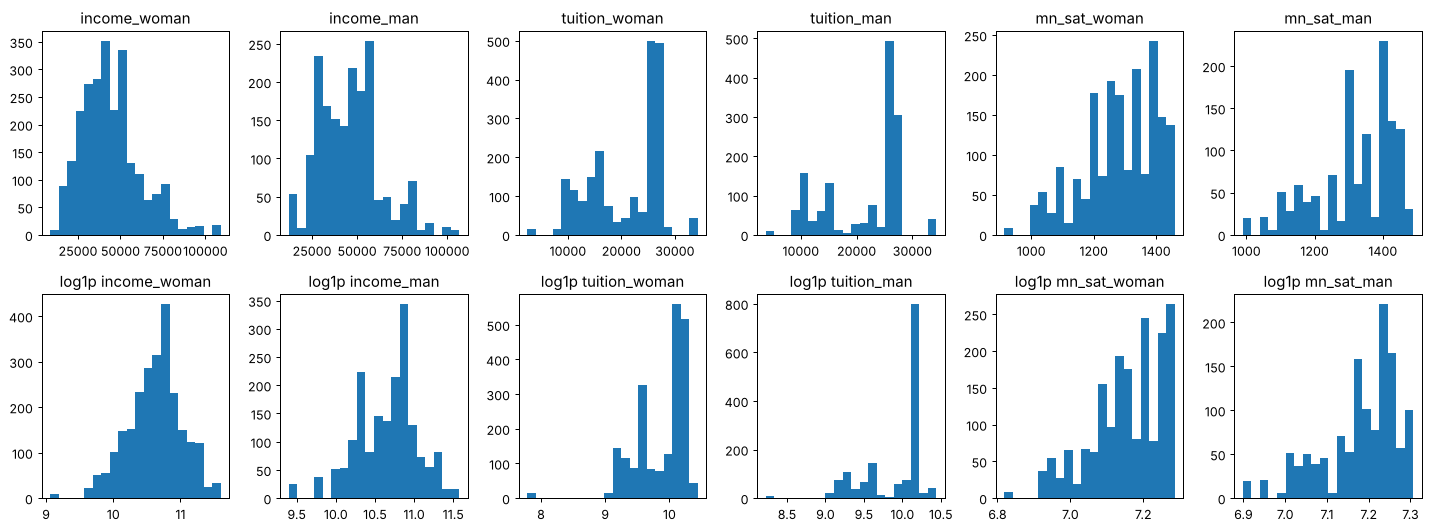

In [8]:
right_skewed_money_and_sat_columns = [
    "income_woman", "income_man",
    "tuition_woman", "tuition_man",
    "mn_sat_woman", "mn_sat_man",
]

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for column_index, column in enumerate(right_skewed_money_and_sat_columns):
    values = meetings[column].dropna()
    axes[0, column_index].hist(values, bins=20)
    axes[0, column_index].set_title(column)
    axes[1, column_index].hist(np.log1p(values), bins=20)
    axes[1, column_index].set_title("log1p " + column)
fig.tight_layout()
plt.show()

for column in right_skewed_money_and_sat_columns:
    meetings["log1p_" + column] = np.log1p(meetings[column])

Distribution notes

Ages cluster in the early 20s. Interest correlation is roughly symmetric around zero. Preference allocations and happiness expectations are bounded scales. Income, tuition, and median SAT are right-skewed; log1p reduces that skew.

8. Correlation matrix

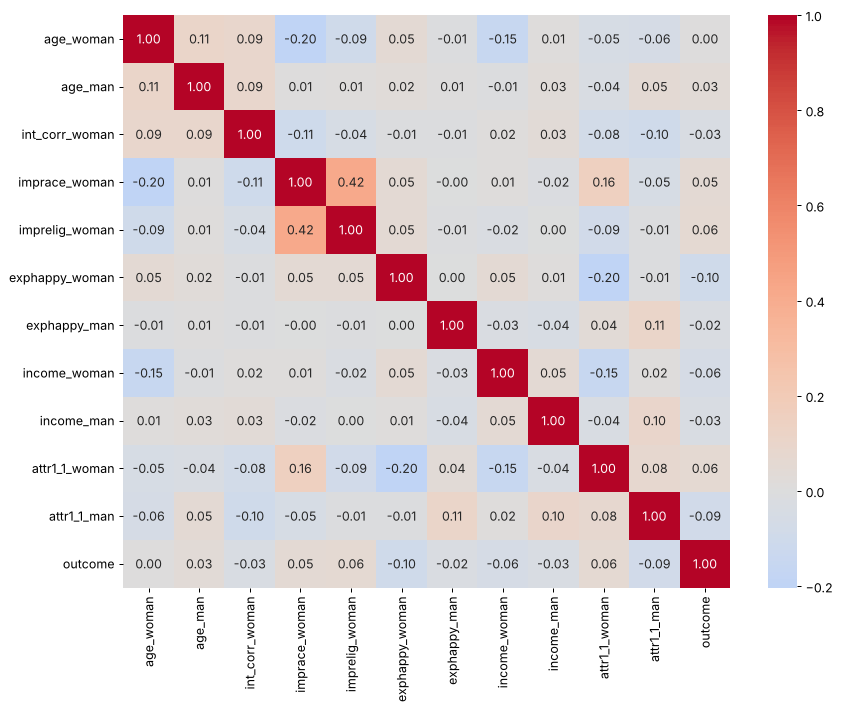

                age_woman   age_man  int_corr_woman  imprace_woman  imprelig_woman  exphappy_woman  exphappy_man  \
age_woman        1.000000  0.106928        0.089017      -0.202898       -0.092607        0.052496     -0.009349   
age_man          0.106928  1.000000        0.091029       0.007027        0.010677        0.022893      0.005449   
int_corr_woman   0.089017  0.091029        1.000000      -0.108016       -0.043627       -0.006203     -0.009520   
imprace_woman   -0.202898  0.007027       -0.108016       1.000000        0.420653        0.046933     -0.004807   
imprelig_woman  -0.092607  0.010677       -0.043627       0.420653        1.000000        0.051601     -0.009136   
exphappy_woman   0.052496  0.022893       -0.006203       0.046933        0.051601        1.000000      0.001203   
exphappy_man    -0.009349  0.005449       -0.009520      -0.004807       -0.009136        0.001203      1.000000   
income_woman    -0.148570 -0.005933        0.015826       0.009340      

In [9]:
correlation_columns = [
    "age_woman", "age_man",
    "int_corr_woman",
    "imprace_woman", "imprelig_woman",
    "exphappy_woman", "exphappy_man",
    "income_woman", "income_man",
    "attr1_1_woman", "attr1_1_man",
    "outcome",
]

correlation_matrix = meetings[correlation_columns].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout()
plt.show()
display(correlation_matrix)

9. Pairplot

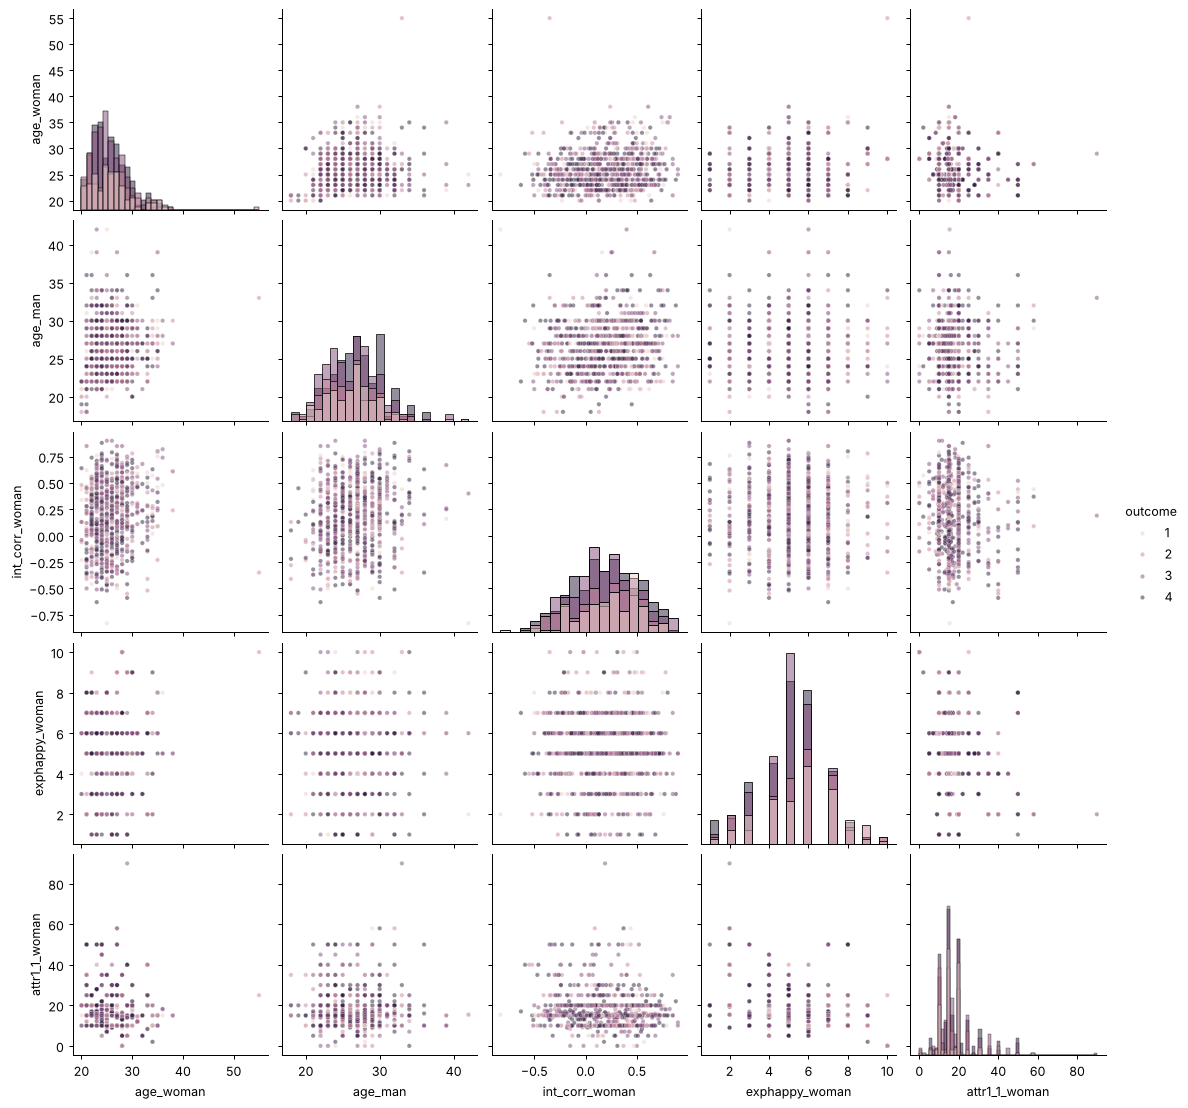

In [10]:
pairplot_columns = [
    "age_woman",
    "age_man",
    "int_corr_woman",
    "exphappy_woman",
    "attr1_1_woman",
    "outcome",
]

pairplot_sample = meetings[pairplot_columns].dropna()
if len(pairplot_sample) > 800:
    pairplot_sample = pairplot_sample.sample(800, random_state=42)

sns.pairplot(
    pairplot_sample,
    hue="outcome",
    diag_kind="hist",
    plot_kws={"alpha": 0.5, "s": 12},
)
plt.show()

10. Podział train / test – grupowy po falach (`wave`)

Jedna osoba odbywa 10–22 spotkań w tej samej fali, więc losowy podział wierszy umieściłby tę samą osobę w train i test (przeciek informacji o osobie). Dzielimy całe fale: każda fala trafia w całości do train albo do test. Ziarno 42, ok. 20% fal w teście. Indeksy fal testowych zapisujemy w `data/test_waves.txt`.

In [11]:
from sklearn.model_selection import GroupShuffleSplit

feature_and_target_columns = [
    column for column in meetings.columns if not column.startswith("log1p_")
]
meetings_for_split = meetings[feature_and_target_columns]

# obie osoby ze spotkania są z tej samej fali, więc wave_woman == wave_man
assert (meetings_for_split["wave_woman"] == meetings_for_split["wave_man"]).all()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(splitter.split(meetings_for_split, groups=meetings_for_split["wave_woman"]))
meetings_train = meetings_for_split.iloc[train_index]
meetings_test = meetings_for_split.iloc[test_index]

test_waves = sorted(int(w) for w in meetings_test["wave_woman"].unique())
participants_train = set(meetings_train["iid_woman"]) | set(meetings_train["iid_man"])
participants_test = set(meetings_test["iid_woman"]) | set(meetings_test["iid_man"])

print("fale w teście", test_waves)
print("train shape", meetings_train.shape, " test shape", meetings_test.shape)
print("udział testu", round(len(meetings_test) / len(meetings_for_split), 3))
print("wspólni uczestnicy train/test", len(participants_train & participants_test))
print("udział klas outcome (train):", meetings_train["outcome"].value_counts(normalize=True).sort_index().round(3).to_dict())
print("udział klas outcome (test): ", meetings_test["outcome"].value_counts(normalize=True).sort_index().round(3).to_dict())

meetings_train.to_csv(Path("data") / "meetings_train.csv", index=False)
meetings_test.to_csv(Path("data") / "meetings_test.csv", index=False)
(Path("data") / "test_waves.txt").write_text(" ".join(map(str, test_waves)) + "\n")
print("zapisano data/meetings_train.csv, data/meetings_test.csv, data/test_waves.txt")

fale w teście [1, 2, 9, 16, 18]
train shape (3296, 173)  test shape (888, 173)
udział testu 0.212
wspólni uczestnicy train/test 0
udział klas outcome (train): {1: 0.167, 2: 0.214, 3: 0.288, 4: 0.331}
udział klas outcome (test):  {1: 0.157, 2: 0.15, 3: 0.391, 4: 0.303}
zapisano data/meetings_train.csv, data/meetings_test.csv, data/test_waves.txt
